# Unsupervised Learning – Clustering: Philippine Earthquakes (USGS)

**Business question:** Can we identify distinct seismic zones in the Philippines based on earthquake location and depth, to support disaster preparedness and risk planning?

**Who benefits:** LGUs and NDRRMC (preparedness priorities), insurance companies (premiums by area), real estate developers and engineers (site selection, building standards), and businesses (safer locations for warehouses, data centers, and branches).

**Approach:** There is no target label, so we let the algorithms find natural groupings.
- **Features:** `latitude`, `longitude`, `depth` (standardized). Magnitude is tested as an optional 4th feature.
- **Main model:** K-Means. **Comparison model:** DBSCAN.
- **Success metrics:** Silhouette Score (closer to 1), a clear bend in the Elbow curve, and clusters that make geographic sense on a map.

**Dataset:** [USGS Earthquake Catalog (ComCat)](https://earthquake.usgs.gov/earthquakes/search/), filtered to the Philippine region. USGS data is in the public domain.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
eq = pd.read_csv("Philippine_Earthquakes_USGS.csv")
eq["time"] = pd.to_datetime(eq["time"], format="mixed")

print("Shape:", eq.shape)
print("Date range:", eq["time"].min().date(), "to", eq["time"].max().date())
eq[["time", "latitude", "longitude", "depth", "mag", "place"]].head()

Shape: (27697, 29)
Date range: 1901-12-15 to 2026-10-16


,time,latitude,longitude,depth,mag,place
0,2026-10-16 20:18:25.421,6.0268,125.7789,10.000,4.7,"10 km SE of Lamitan, Philippines"
1,2026-10-16 17:13:44.909,7.8392,126.7990,73.712,4.9,"31 km ENE of Kinablangan, Philippines"
2,2026-10-13 23:21:44.242,5.3478,125.5183,65.699,4.8,"8 km SE of Sarangani, Philippines"
3,2026-10-13 14:01:24.155,19.6853,120.7047,10.000,4.7,"124 km N of Pagudpud, Philippines"
4,2026-10-11 10:35:35.917,5.4706,126.6164,121.250,4.6,"109 km SSE of Pondaguitan, Philippines"


## 2. Clean the data

- **Filter to 1975 onward.** Before 1975 mainly large quakes were recorded, so older years would bias the zones toward big events.
- **Drop the rows with missing depth**, since depth is one of the clustering features.

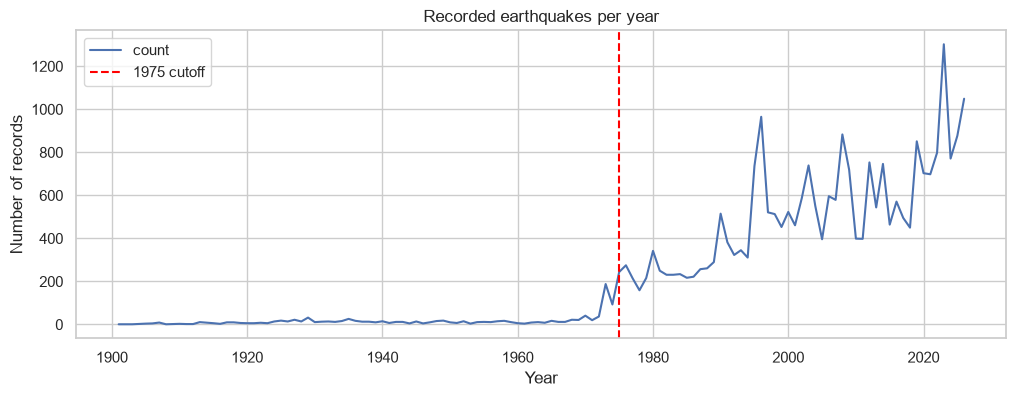

In [ ]:
yearly = eq["time"].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
yearly.plot(ax=ax)
ax.axvline(1975, color="red", linestyle="--", label="1975 cutoff")
ax.set(title="Recorded earthquakes per year", xlabel="Year", ylabel="Number of records")
ax.legend()
plt.show()

In [4]:
print("Records before 1975:", (eq["time"].dt.year < 1975).sum())
print("Missing depth:", eq["depth"].isna().sum())

quakes = eq[eq["time"].dt.year >= 1975].dropna(subset=["depth"]).reset_index(drop=True)
print("Rows used for clustering:", len(quakes))
quakes[["latitude", "longitude", "depth", "mag"]].describe().round(2)

Records before 1975: 1088
Missing depth: 2
Rows used for clustering: 26609


,latitude,longitude,depth,mag
count,26609.00,26609.00,26609.00,25598.00
mean,9.95,124.65,70.10,4.53
std,4.63,2.40,99.38,0.74
min,2.24,117.18,0.70,0.00
25%,6.00,122.56,33.00,4.30
50%,9.28,125.68,35.00,4.50
75%,13.10,126.55,74.40,4.80
max,24.94,135.44,678.00,7.90


Only 1,088 quakes were recorded in the 74 years before 1975 (about 15 a year), compared with about 26,600 since (roughly 500 a year). The jump reflects better monitoring, not more earthquakes, which supports the 1975 cutoff.

## 3. Exploratory data analysis

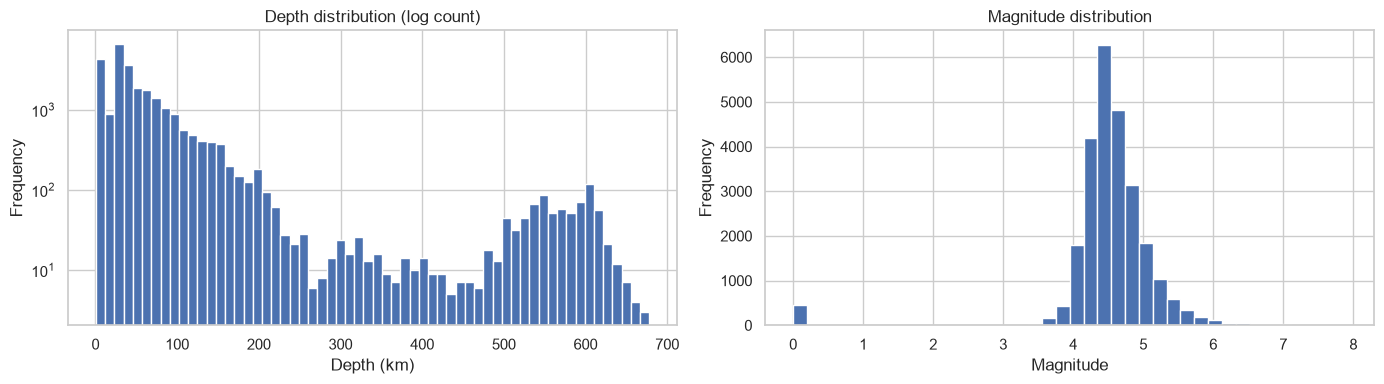

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
quakes["depth"].plot.hist(bins=60, ax=axes[0], log=True)
axes[0].set(title="Depth distribution (log count)", xlabel="Depth (km)")
quakes["mag"].plot.hist(bins=40, ax=axes[1])
axes[1].set(title="Magnitude distribution", xlabel="Magnitude")
plt.tight_layout()
plt.show()

**Depth** is strongly right-skewed: the median is 35 km and 75% of quakes are shallower than about 74 km, but a long tail reaches 678 km. These deep quakes are an outlier group worth separating, not noise to remove. **Magnitude** is concentrated between 4.3 and 4.8 (the catalog mostly records M4.5+ events), and about 1,000 quakes have no magnitude, which is one reason magnitude is only tested as an optional feature.

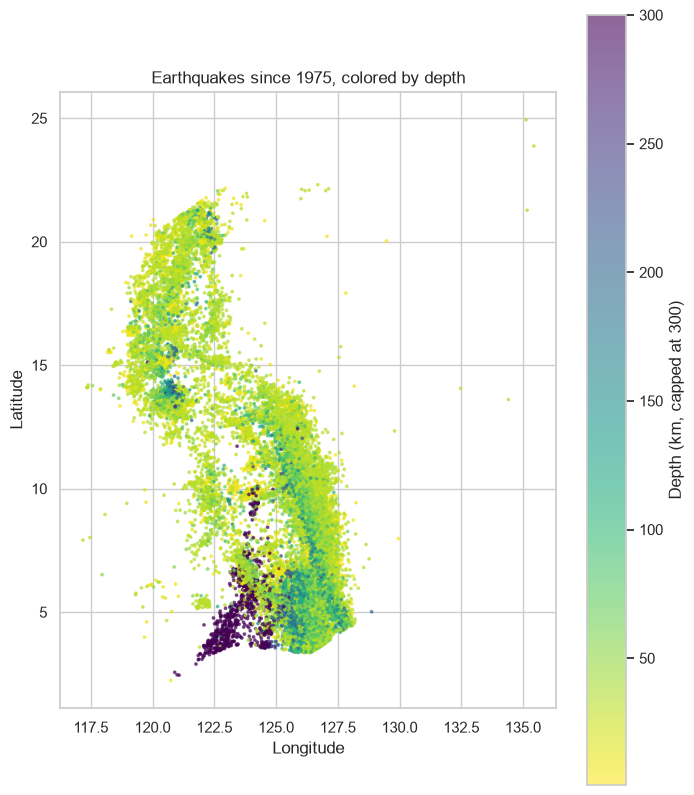

In [6]:
fig, ax = plt.subplots(figsize=(8, 10))
sc = ax.scatter(quakes["longitude"], quakes["latitude"], c=quakes["depth"],
                cmap="viridis_r", s=3, alpha=0.6, vmax=300)
plt.colorbar(sc, label="Depth (km, capped at 300)")
ax.set(title="Earthquakes since 1975, colored by depth", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect("equal")
plt.show()

The plot traces the archipelago's outline. Most quakes are shallow (median depth about 35 km), but a separate group of deep quakes (hundreds of km) sits in the southwest, around the Celebes and Sulu Seas.

## 4. Prepare features

In [7]:
FEATURES = ["latitude", "longitude", "depth"]
scaler = StandardScaler()
X = scaler.fit_transform(quakes[FEATURES])
X.shape

(26609, 3)

## 5. K-Means: choose the number of clusters

We try k = 2 to 10 and compare the **Elbow** (inertia) and **Silhouette Score**. Silhouette uses a 10,000-point sample to keep it fast.

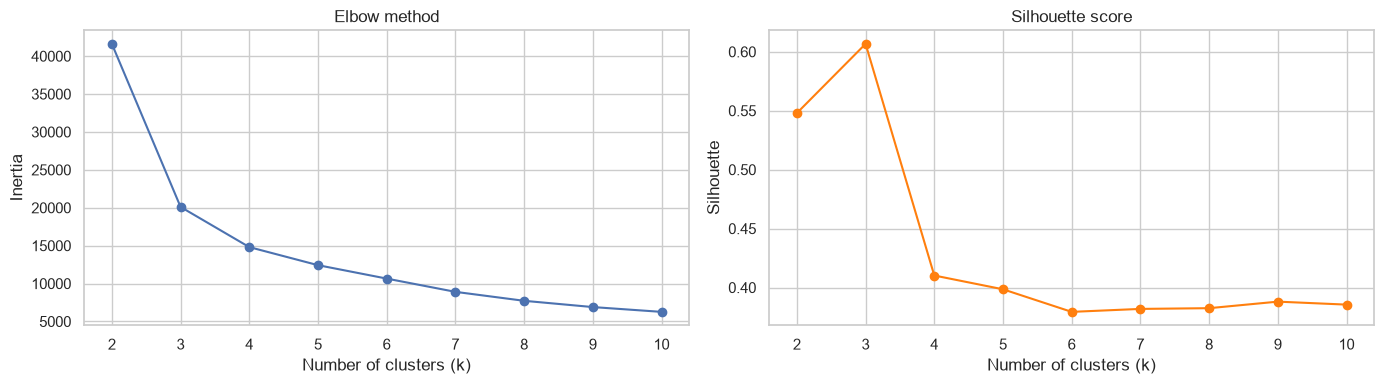

,k,inertia,silhouette
0,2,41617.0,0.548
1,3,20104.0,0.607
2,4,14807.0,0.410
3,5,12423.0,0.398
4,6,10654.0,0.379
5,7,8904.0,0.382
6,8,7723.0,0.382
7,9,6897.0,0.388
8,10,6263.0,0.385


In [8]:
ks = range(2, 11)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_, sample_size=10000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(ks, silhouettes, marker="o", color="tab:orange")
axes[1].set(title="Silhouette score", xlabel="Number of clusters (k)", ylabel="Silhouette")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": ks, "inertia": np.round(inertias), "silhouette": np.round(silhouettes, 3)})

**k = 3** gives the highest silhouette and sits at the bend of the elbow curve, where inertia drops sharply up to k = 3 and then flattens. We use k = 3.

## 6. Final K-Means model (k = 3)

In [9]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X)
quakes["kmeans_cluster"] = kmeans.labels_
kmeans_silhouette = silhouette_score(X, kmeans.labels_, sample_size=10000, random_state=RANDOM_STATE)
print(f"K-Means silhouette (k=3): {kmeans_silhouette:.3f}")

centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES).round(2)
centers

K-Means silhouette (k=3): 0.607


,latitude,longitude,depth
0,16.06,121.15,46.66
1,7.84,126.06,55.57
2,5.39,123.64,525.28


In [10]:
profile = quakes.groupby("kmeans_cluster").agg(
    quakes=("id", "size"),
    lat_mean=("latitude", "mean"),
    lon_mean=("longitude", "mean"),
    depth_mean=("depth", "mean"),
    depth_median=("depth", "median"),
    mag_mean=("mag", "mean"),
    mag_max=("mag", "max"),
    strong_quakes_m6=("mag", lambda m: (m >= 6).sum()),
).round(2)
profile["share_%"] = (profile["quakes"] / profile["quakes"].sum() * 100).round(1)
profile

,quakes,lat_mean,lon_mean,depth_mean,depth_median,mag_mean,mag_max,strong_quakes_m6,share_%
kmeans_cluster,,,,,,,,,
0,7126,16.06,121.14,46.67,33.00,4.44,7.7,67,26.8
1,18525,7.84,126.06,55.57,35.20,4.56,7.9,228,69.6
2,958,5.39,123.64,525.28,550.74,4.54,7.6,24,3.6


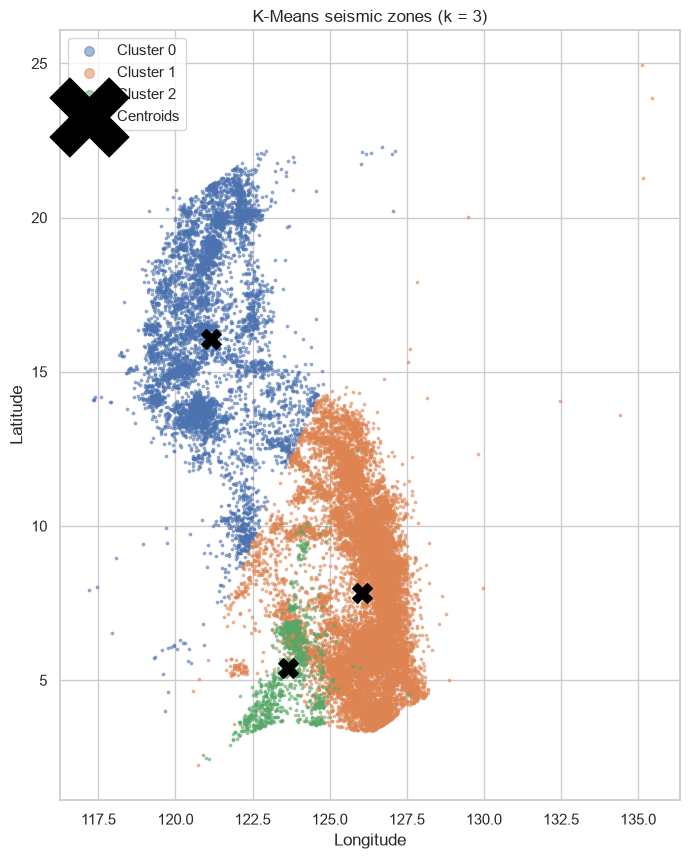

In [11]:
fig, ax = plt.subplots(figsize=(8, 10))
for c in sorted(quakes["kmeans_cluster"].unique()):
    part = quakes[quakes["kmeans_cluster"] == c]
    ax.scatter(part["longitude"], part["latitude"], s=3, alpha=0.5, label=f"Cluster {c}")
ax.scatter(centers["longitude"], centers["latitude"], c="black", marker="X", s=200, label="Centroids")
ax.set(title="K-Means seismic zones (k = 3)", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect("equal")
ax.legend(markerscale=4)
plt.show()

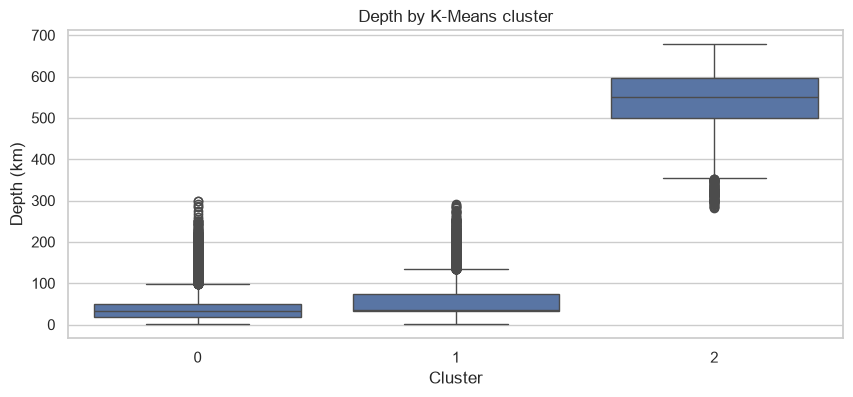

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=quakes, x="kmeans_cluster", y="depth", ax=ax)
ax.set(title="Depth by K-Means cluster", xlabel="Cluster", ylabel="Depth (km)")
plt.show()

**Interpreting the three zones**

| Cluster | Zone | What it means for planning |
|---|---|---|
| 0 | **Northern zone (Luzon and north)**, shallow, about 27% of quakes | Shallow quakes near population centers such as Metro Manila and Baguio. Strong shaking risk for buildings and infrastructure. |
| 1 | **Eastern Visayas and Mindanao zone**, shallow, about 70% of quakes and most M6+ events | The most active zone, along the Philippine Trench side. Highest priority for preparedness and insurance pricing. |
| 2 | **Deep zone (under the Celebes Sea, southwest of Mindanao)**, median depth about 550 km | Many quakes, but very deep, so surface shaking is usually weaker. Lower building risk than a shallow quake of the same magnitude. |

K-Means mostly split the shallow quakes north vs south and separated out the deep quakes, which matches the geography.

## 7. DBSCAN comparison

DBSCAN does not need k. It groups dense regions of any shape and labels isolated quakes as **noise** (-1), which suits long, narrow fault lines better than K-Means' round clusters.

We set `min_samples = 20` and read `eps` from the k-distance plot: the distance to each point's 20th nearest neighbor, sorted. The bend in that curve suggests a reasonable `eps`.

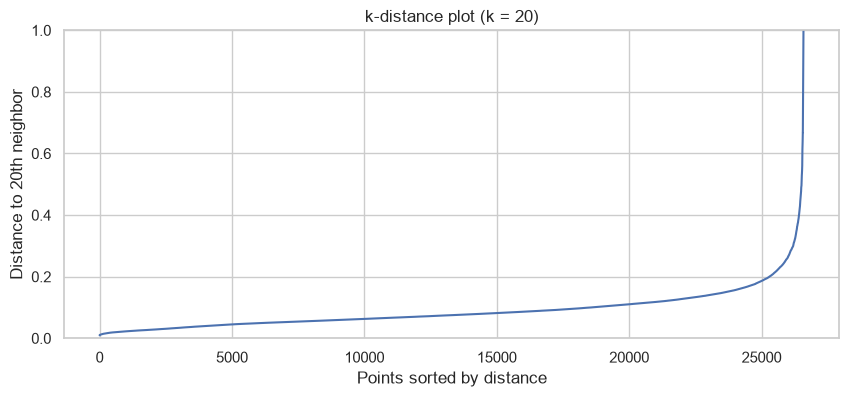

In [13]:
MIN_SAMPLES = 20
distances, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)
k_dist = np.sort(distances[:, -1])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(k_dist)
ax.set(title=f"k-distance plot (k = {MIN_SAMPLES})", xlabel="Points sorted by distance",
       ylabel=f"Distance to {MIN_SAMPLES}th neighbor", ylim=(0, 1))
plt.show()

In [14]:
def dbscan_summary(eps):
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    sil = (silhouette_score(X[mask], labels[mask], sample_size=10000, random_state=RANDOM_STATE)
           if n_clusters > 1 else np.nan)
    return {"eps": eps, "clusters": n_clusters, "noise_%": round((~mask).mean() * 100, 1),
            "silhouette (non-noise)": round(sil, 3)}

pd.DataFrame([dbscan_summary(eps) for eps in [0.15, 0.2, 0.25, 0.3, 0.4, 0.5]])

,eps,clusters,noise_%,silhouette (non-noise)
0,0.15,6,4.8,-0.137
1,0.20,5,2.1,0.055
2,0.25,5,1.0,0.285
3,0.30,2,0.6,0.578
4,0.40,1,0.3,NaN
5,0.50,1,0.2,NaN


In [15]:
DBSCAN_EPS = 0.25
quakes["dbscan_cluster"] = DBSCAN(eps=DBSCAN_EPS, min_samples=MIN_SAMPLES).fit_predict(X)
dbscan_result = dbscan_summary(DBSCAN_EPS)
print(dbscan_result)

quakes.groupby("dbscan_cluster").agg(
    quakes=("id", "size"),
    lat_mean=("latitude", "mean"),
    lon_mean=("longitude", "mean"),
    depth_mean=("depth", "mean"),
    mag_mean=("mag", "mean"),
).round(2)

{'eps': 0.25, 'clusters': 5, 'noise_%': np.float64(1.0), 'silhouette (non-noise)': 0.285}


,quakes,lat_mean,lon_mean,depth_mean,mag_mean
dbscan_cluster,,,,,
-1,266,10.44,123.44,189.95,4.40
0,25368,10.08,124.71,52.27,4.53
1,724,5.30,123.39,566.27,4.55
2,158,4.61,124.62,345.21,4.44
3,69,20.59,122.19,164.59,4.50
4,24,9.28,124.14,530.65,4.77


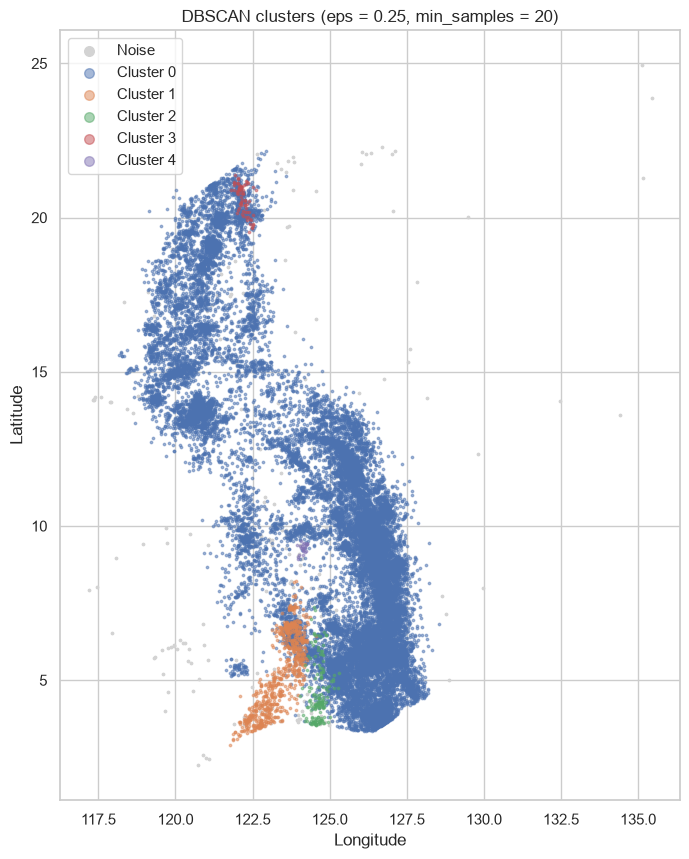

In [16]:
fig, ax = plt.subplots(figsize=(8, 10))
noise = quakes[quakes["dbscan_cluster"] == -1]
ax.scatter(noise["longitude"], noise["latitude"], s=3, c="lightgrey", label="Noise")
for c in sorted(quakes.loc[quakes["dbscan_cluster"] != -1, "dbscan_cluster"].unique()):
    part = quakes[quakes["dbscan_cluster"] == c]
    ax.scatter(part["longitude"], part["latitude"], s=3, alpha=0.5, label=f"Cluster {c}")
ax.set(title=f"DBSCAN clusters (eps = {DBSCAN_EPS}, min_samples = {MIN_SAMPLES})",
       xlabel="Longitude", ylabel="Latitude")
ax.set_aspect("equal")
ax.legend(markerscale=4)
plt.show()

**K-Means vs DBSCAN**

- With `eps = 0.3` or larger, DBSCAN merges almost everything into one cluster. Its silhouette looks high, but it tells us nothing useful. We use `eps = 0.25`.
- At `eps = 0.25`, DBSCAN puts the shallow quakes into **one connected band** and then finds several smaller **deep and intermediate-depth pockets**: under the Celebes Sea, south of Mindanao, north of Luzon, and a small deep group under the central Visayas. About 1% of quakes are flagged as noise.
- Its silhouette is lower than K-Means' because the pockets are close together in depth and uneven in size. However, DBSCAN shows that shallow seismicity forms one continuous belt along the whole archipelago, which K-Means' round clusters cut into north and south.

**Conclusion:** K-Means (k = 3) is the main model. It has the best silhouette and gives simple, explainable zones. DBSCAN is the comparison: it adds detail on deep pockets and isolated quakes.

## 8. Optional: add magnitude as a 4th feature

Rows without a magnitude are dropped for this test only.

In [17]:
with_mag = quakes.dropna(subset=["mag"])
X_mag = StandardScaler().fit_transform(with_mag[FEATURES + ["mag"]])
mag_scores = {}
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_mag)
    mag_scores[k] = round(silhouette_score(X_mag, labels, sample_size=10000, random_state=RANDOM_STATE), 3)
print("Rows with magnitude:", len(with_mag))
print("Silhouette by k with magnitude:", mag_scores)

Rows with magnitude: 25598
Silhouette by k with magnitude: {2: 0.472, 3: 0.525, 4: 0.544, 5: 0.334, 6: 0.333}


Adding magnitude **lowers** the best silhouette (about 0.54 vs 0.61). Magnitude is spread fairly evenly across locations, so it blurs the zones instead of separating them. We keep the 3-feature model.

## 9. Results vs success metrics

In [18]:
pd.DataFrame([
    {"Metric": "Silhouette (K-Means, k=3)", "Target": "Closer to 1 (benchmark ~0.60)", "Result": round(kmeans_silhouette, 3)},
    {"Metric": "Silhouette (DBSCAN, non-noise)", "Target": "Comparison", "Result": dbscan_result["silhouette (non-noise)"]},
    {"Metric": "DBSCAN noise share", "Target": "Comparison", "Result": f"{dbscan_result['noise_%']}%"},
    {"Metric": "Elbow method", "Target": "Clear bend", "Result": "Bend at k = 3"},
    {"Metric": "Interpretability", "Target": "Clusters make geographic sense", "Result": "See zone maps above"},
])

,Metric,Target,Result
0,"Silhouette (K-Means, k=3)",Closer to 1 (benchmark ~0.60),0.607
1,"Silhouette (DBSCAN, non-noise)",Comparison,0.285
2,DBSCAN noise share,Comparison,1.0%
3,Elbow method,Clear bend,Bend at k = 3
4,Interpretability,Clusters make geographic sense,See zone maps above


## 10. Assumptions, limitations, and next steps

**Assumptions**
- Past earthquake locations indicate where future earthquakes are likely.
- Location and depth are enough to define meaningful zones.
- The USGS records are accurate.

**Limitations**
- Records before 1975 are incomplete, so they were filtered out.
- Clusters show **where** quakes happen, not **when** the next one will occur. This is not earthquake prediction.
- K-Means assumes round clusters, while fault lines are long and narrow, which is why DBSCAN serves as a comparison.
- Latitude, longitude, and depth are scaled independently, so "distance" between quakes mixes degrees and kilometers. Zones are a statistical grouping, not official fault boundaries (see PHIVOLCS for those).

**Suggested next steps**
- Convert latitude and longitude to kilometers so all three features use the same unit before clustering.
- Try HDBSCAN, which handles clusters of different density better than DBSCAN with a single `eps`.
- Overlay PHIVOLCS fault lines and population data to turn the zones into a risk map.

**What this model should not be used for**
- Predicting when or where the next earthquake will happen.
- Replacing official PHIVOLCS hazard maps or building codes.
- Site-specific engineering decisions. The zones are too coarse and do not measure ground shaking or soil conditions.